<a href="https://colab.research.google.com/github/EniodeSousa/FNO_Experiments/blob/main/fno_burgers_1d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fourier Neural Operator for the 1-d viscous Burgers equation

Reproduces Section 5.1 of Li et al., *Fourier Neural Operator for Parametric PDEs* (ICLR 2021):

$$u_t + \partial_x(u^2/2) = \nu\, u_{xx},\quad x\in\mathbb{T}=[0,1)\ \text{(periodic)},\quad \nu = 0.1,$$

and learns the solution operator $G^\dagger: u_0 \mapsto u(\cdot, 1)$.

**Pipeline**
1. Sample $u_0 \sim \mu = N\big(0,\ 625(-\Delta + 25 I)^{-2}\big)$ (periodic), as in Appendix A.3.1.
2. Solve to $t=1$ with a pseudo-spectral method on a fine grid (default 8192 points, as in the paper).
3. Subsample to the training resolution and train an FNO (4 Fourier layers, $k_{\max}=16$, $d_v=64$).
4. Plots: data, learning curves, predictions, error distribution, Fourier spectra, and
   zero-shot evaluation at resolutions never seen in training.

Runtime: select **Runtime → Change runtime type → T4 GPU**. With the defaults, data generation
takes a few minutes and training about 5–10 minutes. Set `FAST = True` below for a quick test run.

## 0. Setup and parameters

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (this will be slow)")
torch.manual_seed(0); np.random.seed(0)

FAST = False            # True: small, quick run to check that everything works

# --- PDE and data (paper, Appendix A.3.1) ---
NU       = 0.1          # viscosity
T_FINAL  = 1.0          # learn u0 -> u(., T_FINAL)
N_SOLVE  = 8192         # resolution of the reference solver (paper: 2^13 = 8192)
N_TRAIN  = 1000         # training pairs (paper: 1000)
N_TEST   = 200          # test pairs     (paper: 200)

# --- FNO (paper, Section 5) ---
S_TRAIN  = 1024         # training resolution (subsampled from N_SOLVE); paper sweeps 256 ... 8192
MODES    = 16           # k_max,j for the 1-d problem
WIDTH    = 64           # d_v, number of channels
LAYERS   = 4            # Fourier layers
ACT      = "gelu"       # authors' released code uses GELU; the paper text says ReLU + batch norm
USE_BN   = False        # set True (with ACT="relu") to follow the paper text literally

# --- training (paper: Adam, lr 1e-3 halved every 100 epochs, 500 epochs) ---
EPOCHS     = 500
BATCH      = 20
LR         = 1e-3
STEP       = 100
GAMMA      = 0.5
WEIGHT_DEC = 1e-4

if FAST:
    N_SOLVE, N_TRAIN, N_TEST, S_TRAIN, EPOCHS, STEP = 1024, 200, 50, 256, 30, 10

assert N_SOLVE % S_TRAIN == 0, "S_TRAIN must divide N_SOLVE (we subsample by striding)"

device: cuda | Tesla T4


**A note on the viscosity.** With the paper's stated values ($\nu=0.1$ on $[0,1]$, $T=1$), diffusion
damps the $k=1$ mode by $e^{-4\pi^2\nu}\approx 0.02$, so the fluctuations of $u$ shrink roughly
60-fold by $t=1$: the output is essentially the conserved mean $\int u_0$ plus a small ripple.
The learning problem is then fairly easy, and the relative error is dominated by samples whose mean
is close to zero. For a more interesting operator, with steep fronts, also try `NU = 0.01`
(the value used in the later PINO paper). Everything below works unchanged.

## 1. Initial conditions: a Gaussian random field on the torus

The covariance operator $C = 625(-\Delta+25I)^{-2}$ is diagonal in the Fourier basis
$e_k(x)=e^{2\pi i k x}$ with eigenvalues $\lambda_k = 625\,(4\pi^2k^2+25)^{-2}$.
A sample is the Karhunen–Loève series $u_0=\sum_k \sqrt{\lambda_k}\,\xi_k e_k$ with independent
standard Gaussian $\xi_k$ and $\xi_{-k}=\overline{\xi_k}$ (so $u_0$ is real).

In [2]:
def sample_grf_1d(n_samples, n, alpha=2.0, tau=5.0, sigma=25.0, device=device, dtype=torch.float64):
    """Samples of N(0, sigma^2 (-Lap + tau^2 I)^(-alpha)) on [0,1), periodic, at n grid points."""
    k = torch.fft.rfftfreq(n, d=1.0 / n).to(device=device, dtype=dtype)          # 0, 1, ..., n/2
    sqrt_lam = sigma * (4 * math.pi**2 * k**2 + tau**2) ** (-alpha / 2)          # sqrt(lambda_k)
    re = torch.randn(n_samples, k.numel(), device=device, dtype=dtype)
    im = torch.randn(n_samples, k.numel(), device=device, dtype=dtype)
    xi = torch.complex(re, im) / math.sqrt(2)                                    # E|xi_k|^2 = 1
    xi[:, 0] = re[:, 0].to(xi.dtype)                                             # k = 0 mode is real
    if n % 2 == 0:
        xi[:, -1] = re[:, -1].to(xi.dtype)                                       # Nyquist mode is real
    coef = sqrt_lam * xi
    return torch.fft.irfft(coef, n=n, norm="forward")                             # u(x_j) = sum_k c_k e^{2 pi i k x_j}

## 2. Reference solver: pseudo-spectral, integrating-factor RK4

Write $\hat u_t = -\nu(2\pi k)^2\hat u + \hat N(\hat u)$ with $\hat N(\hat u) = -\tfrac{i}{2}(2\pi k)\,\widehat{u^2}$.
The linear (heat) part is integrated **exactly** through the integrating factor $e^{-\nu(2\pi k)^2 t}$;
the nonlinear part with classical RK4, the product $u^2$ computed in physical space with the 2/3
dealiasing rule. (The paper uses a split-step method: exact heat step plus a very fine forward-Euler
step for the nonlinearity; both treat the heat part exactly. RK4 is simply more accurate per step.)

By the maximum principle $\max|u(\cdot,t)|\le\max|u_0|$, so a time step fixed from $u_0$ stays stable.

In [3]:
@torch.no_grad()
def burgers_solve(u0, nu=NU, T=T_FINAL, cfl=1.0, n_snap=0):
    """u0: (B, n) real tensor on a uniform periodic grid. Returns u(., T) (B, n) and optional snapshots."""
    B, n = u0.shape
    dtype = u0.dtype
    kk = 2 * math.pi * torch.fft.rfftfreq(n, d=1.0 / n).to(u0.device, dtype)      # angular wavenumbers
    dealias = (torch.arange(kk.numel(), device=u0.device) <= n // 3).to(dtype)    # 2/3 rule
    umax = u0.abs().max().item()
    # RK4 is stable on the imaginary axis up to |z| ~ 2.8; fastest advective mode: umax * (2 pi n / 3)
    dt = cfl / (umax * n + 1e-12)
    n_steps = int(math.ceil(T / dt)); dt = T / n_steps
    E  = torch.exp(-nu * kk**2 * dt / 2)
    E2 = E * E
    ik = 1j * kk

    def N(uh):
        u = torch.fft.irfft(uh * dealias, n=n)
        return -0.5 * ik * torch.fft.rfft(u * u)

    uh = torch.fft.rfft(u0)
    snaps, snap_every = [], max(1, n_steps // max(n_snap, 1))
    for step in range(n_steps):
        if n_snap and step % snap_every == 0:
            snaps.append(torch.fft.irfft(uh, n=n)[0].cpu())
        k1 = N(uh)
        k2 = N(E * (uh + 0.5 * dt * k1))
        k3 = N(E * uh + 0.5 * dt * k2)
        k4 = N(E2 * uh + dt * E * k3)
        uh = E2 * uh + dt / 6 * (E2 * k1 + 2 * E * (k2 + k3) + k4)
    uT = torch.fft.irfft(uh, n=n)
    if n_snap:
        snaps.append(uT[0].cpu())
        return uT, torch.stack(snaps), n_steps
    return uT, None, n_steps

**Sanity check of the solver against the exact solution.** By the Cole–Hopf transform, if $\int u_0 = 0$,
then $u = -2\nu\,\varphi_x/\varphi$ where $\varphi$ solves the heat equation $\varphi_t=\nu\varphi_{xx}$ with
$\varphi(x,0)=\exp\!\big(-\tfrac{1}{2\nu}\int_0^x u_0\big)$. We compute $\varphi$ exactly in Fourier space
and compare. The error should be close to machine precision.

In [4]:
def cole_hopf(u0, nu=NU, T=T_FINAL):
    n = u0.shape[-1]
    k = 2 * math.pi * torch.fft.fftfreq(n, d=1.0 / n).to(u0.device, u0.dtype)
    U0h = torch.fft.fft(u0)
    Ih = torch.where(k == 0, torch.zeros_like(U0h), U0h / (1j * k))      # antiderivative (mean-zero u0)
    log_phi0 = -torch.fft.ifft(Ih).real / (2 * nu)
    log_phi0 = log_phi0 - log_phi0.max(dim=-1, keepdim=True).values      # avoid overflow
    ph = torch.fft.fft(torch.exp(log_phi0)) * torch.exp(-nu * k**2 * T)
    return -2 * nu * torch.fft.ifft(1j * k * ph).real / torch.fft.ifft(ph).real

u0_chk = sample_grf_1d(4, N_SOLVE)
u0_chk = u0_chk - u0_chk.mean(dim=-1, keepdim=True)
u_num, _, n_steps = burgers_solve(u0_chk)
u_ex = cole_hopf(u0_chk)
print(f"{n_steps} time steps; max relative error vs Cole-Hopf: "
      f"{((u_num - u_ex).norm(dim=-1) / u_ex.norm(dim=-1)).max():.2e}")

6916 time steps; max relative error vs Cole-Hopf: 1.92e-11


## 3. Generate the dataset
All pairs are generated at `N_SOLVE` points; lower resolutions are obtained by subsampling,
exactly as in the paper. The solver runs in float64 batches on the GPU. The time step is set by the
advective CFL condition, so the cost grows like `N_SOLVE`²: on a T4, expect roughly 10 minutes at 8192
and well under a minute at 1024. The data are saved to `burgers_data_nu{NU}_n{N_SOLVE}.pt` and reloaded
automatically if you re-run the notebook.

In [5]:
import os

def generate(n_samples, n=N_SOLVE, batch=400):
    U0, UT = [], []
    t_start = time.time()
    for i in range(0, n_samples, batch):
        b = min(batch, n_samples - i)
        u0 = sample_grf_1d(b, n)
        uT, _, steps = burgers_solve(u0)
        U0.append(u0.float().cpu()); UT.append(uT.float().cpu())
        elapsed = time.time() - t_start
        eta = elapsed / (i + b) * (n_samples - i - b)
        print(f"  solved {i + b}/{n_samples}  ({steps} time steps per batch, {elapsed:.0f} s elapsed, ~{eta:.0f} s left)")
    return torch.cat(U0), torch.cat(UT)

data_file = f"burgers_data_nu{NU}_n{N_SOLVE}.pt"
if os.path.exists(data_file) and torch.load(data_file)["u0"].shape[0] >= N_TRAIN + N_TEST:
    d = torch.load(data_file); u0_all, uT_all = d["u0"], d["uT"]
    print(f"loaded {data_file}")
else:
    t0 = time.time()
    u0_all, uT_all = generate(N_TRAIN + N_TEST)
    print(f"data generation: {time.time() - t0:.1f} s  | shapes {tuple(u0_all.shape)}")
    torch.save(dict(u0=u0_all, uT=uT_all, nu=NU, n=N_SOLVE), data_file)
u0_train, uT_train = u0_all[:N_TRAIN], uT_all[:N_TRAIN]
u0_test,  uT_test  = u0_all[N_TRAIN:N_TRAIN + N_TEST], uT_all[N_TRAIN:N_TRAIN + N_TEST]

  solved 400/1200  (39633 time steps per batch, 780 s elapsed, ~1561 s left)
  solved 800/1200  (34992 time steps per batch, 1470 s elapsed, ~735 s left)
  solved 1200/1200  (35201 time steps per batch, 2164 s elapsed, ~0 s left)
data generation: 2164.4 s  | shapes (1200, 8192)


### Plot: samples of the data and the evolution of one solution

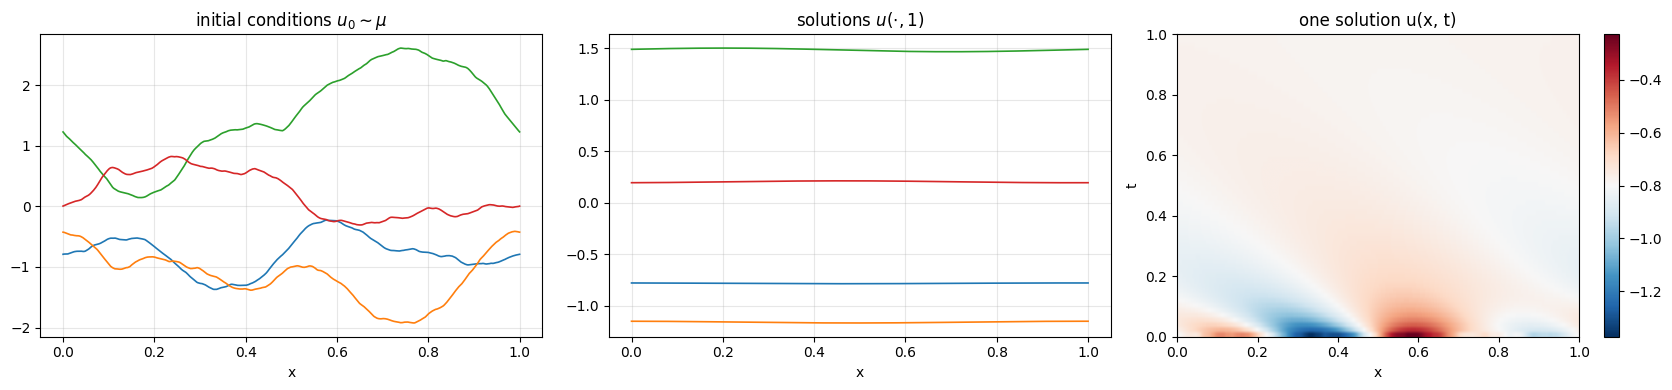

In [6]:
x_full = torch.arange(N_SOLVE) / N_SOLVE
_, snaps, _ = burgers_solve(u0_test[:1].double().to(device), n_snap=60)

fig, axs = plt.subplots(1, 3, figsize=(17, 4))
for i in range(4):
    axs[0].plot(x_full, u0_test[i], lw=1.2)
    axs[1].plot(x_full, uT_test[i], lw=1.2)
axs[0].set_title(r"initial conditions $u_0\sim\mu$"); axs[1].set_title(r"solutions $u(\cdot,1)$")
for ax in axs[:2]: ax.set_xlabel("x"); ax.grid(alpha=.3)
im = axs[2].imshow(snaps.numpy(), aspect="auto", origin="lower", extent=[0, 1, 0, T_FINAL], cmap="RdBu_r")
axs[2].set_xlabel("x"); axs[2].set_ylabel("t"); axs[2].set_title("one solution u(x, t)")
fig.colorbar(im, ax=axs[2]); plt.tight_layout(); plt.show()

## 4. The Fourier Neural Operator
$v_0 = P(u_0(x), x)$, then $v_{t+1} = \sigma\big(W v_t + \mathcal F^{-1}(R\cdot \mathcal F v_t)\big)$ for 4 layers,
keeping only the lowest `MODES` Fourier modes in $R$, and finally $u = Q(v_4)$.

Note `irfft(R * rfft(v))`: the forward FFT is unnormalised and the inverse divides by $n$, so the
composition approximates the same continuum operator at every resolution — this is what makes the
weights resolution-independent.

In [7]:
class SpectralConv1d(nn.Module):
    def __init__(self, c_in, c_out, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / (c_in * c_out)
        self.weight = nn.Parameter(scale * torch.rand(c_in, c_out, modes, dtype=torch.cfloat))

    def forward(self, v):                       # v: (B, C, n)
        B, C, n = v.shape
        vh = torch.fft.rfft(v)                  # (B, C, n//2 + 1)
        m = min(self.modes, vh.shape[-1])
        out = torch.zeros(B, self.weight.shape[1], vh.shape[-1], dtype=torch.cfloat, device=v.device)
        out[:, :, :m] = torch.einsum("bix,iox->box", vh[:, :, :m], self.weight[:, :, :m])
        return torch.fft.irfft(out, n=n)


class FNO1d(nn.Module):
    def __init__(self, modes=MODES, width=WIDTH, layers=LAYERS, act=ACT, use_bn=USE_BN):
        super().__init__()
        self.P = nn.Linear(2, width)                                  # input: (u0(x), x)
        self.spectral = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(layers)])
        self.W = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(layers)])
        self.bn = nn.ModuleList([nn.BatchNorm1d(width) for _ in range(layers)]) if use_bn else None
        self.act = F.gelu if act == "gelu" else F.relu
        self.Q = nn.Sequential(nn.Linear(width, 128), nn.GELU() if act == "gelu" else nn.ReLU(), nn.Linear(128, 1))

    def forward(self, u0):                      # u0: (B, n) on a uniform periodic grid of [0, 1)
        B, n = u0.shape
        x = (torch.arange(n, device=u0.device, dtype=u0.dtype) / n).expand(B, n)
        v = self.P(torch.stack([u0, x], dim=-1)).permute(0, 2, 1)    # (B, width, n)
        for l, (K, W) in enumerate(zip(self.spectral, self.W)):
            v = K(v) + W(v)
            if self.bn is not None: v = self.bn[l](v)
            if l < len(self.spectral) - 1: v = self.act(v)          # no activation after the last layer
        return self.Q(v.permute(0, 2, 1)).squeeze(-1)                # (B, n)


def rel_l2(pred, true):                          # per-sample relative L2 error on the grid
    return (pred - true).norm(dim=-1) / true.norm(dim=-1)

model = FNO1d().to(device)
n_par = sum(p.numel() * (2 if p.is_complex() else 1) for p in model.parameters())
print(f"FNO1d parameters: {n_par:,} (real numbers; complex weights counted twice)")

FNO1d parameters: 549,569 (real numbers; complex weights counted twice)


## 5. Training at resolution `S_TRAIN`

In [8]:
stride = N_SOLVE // S_TRAIN
Xtr, Ytr = u0_train[:, ::stride].to(device), uT_train[:, ::stride].to(device)
Xte, Yte = u0_test[:, ::stride].to(device),  uT_test[:, ::stride].to(device)

@torch.no_grad()
def evaluate(model, X, Y, batch=50):
    model.eval()
    errs = torch.cat([rel_l2(model(X[i:i + batch]), Y[i:i + batch]) for i in range(0, len(X), batch)])
    return errs.cpu()

opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DEC)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=STEP, gamma=GAMMA)
hist = {"train": [], "test": []}
t0 = time.time()
for ep in range(EPOCHS):
    model.train()
    perm = torch.randperm(N_TRAIN, device=device)
    tot = 0.0
    for i in range(0, N_TRAIN, BATCH):
        idx = perm[i:i + BATCH]
        loss = rel_l2(model(Xtr[idx]), Ytr[idx]).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(idx)
    sched.step()
    hist["train"].append(tot / N_TRAIN)
    hist["test"].append(evaluate(model, Xte, Yte).mean().item())
    if ep % max(1, EPOCHS // 20) == 0 or ep == EPOCHS - 1:
        print(f"epoch {ep:4d} | train {hist['train'][-1]:.4f} | test {hist['test'][-1]:.4f} | "
              f"lr {sched.get_last_lr()[0]:.1e} | {time.time() - t0:.0f} s")
torch.save(model.state_dict(), f"fno_burgers_s{S_TRAIN}.pt")
print(f"final test relative L2 error at s={S_TRAIN}: {hist['test'][-1]:.4f}   (paper, FNO: ~0.015)")

epoch    0 | train 0.5065 | test 0.2075 | lr 1.0e-03 | 3 s
epoch   25 | train 0.0591 | test 0.0568 | lr 1.0e-03 | 13 s
epoch   50 | train 0.0476 | test 0.0934 | lr 1.0e-03 | 24 s
epoch   75 | train 0.0253 | test 0.0570 | lr 1.0e-03 | 34 s
epoch  100 | train 0.0302 | test 0.0196 | lr 5.0e-04 | 44 s
epoch  125 | train 0.0153 | test 0.0071 | lr 5.0e-04 | 54 s
epoch  150 | train 0.0189 | test 0.0132 | lr 5.0e-04 | 65 s
epoch  175 | train 0.0190 | test 0.0394 | lr 5.0e-04 | 75 s
epoch  200 | train 0.0076 | test 0.0060 | lr 2.5e-04 | 85 s
epoch  225 | train 0.0086 | test 0.0050 | lr 2.5e-04 | 95 s
epoch  250 | train 0.0105 | test 0.0193 | lr 2.5e-04 | 106 s
epoch  275 | train 0.0102 | test 0.0114 | lr 2.5e-04 | 116 s
epoch  300 | train 0.0062 | test 0.0036 | lr 1.3e-04 | 126 s
epoch  325 | train 0.0055 | test 0.0058 | lr 1.3e-04 | 136 s
epoch  350 | train 0.0028 | test 0.0041 | lr 1.3e-04 | 147 s
epoch  375 | train 0.0045 | test 0.0028 | lr 1.3e-04 | 157 s
epoch  400 | train 0.0027 | test 0.

## 6. Results
### 6a. Learning curves

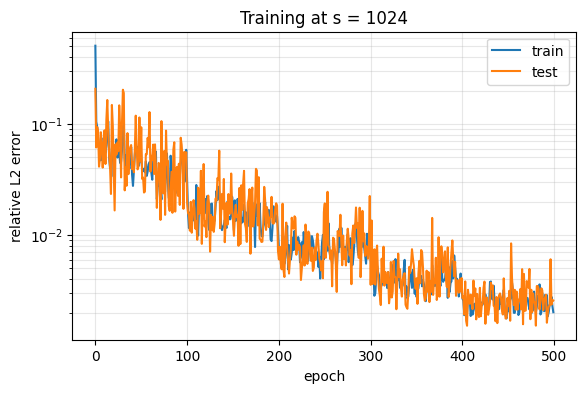

In [9]:
plt.figure(figsize=(6.5, 4))
plt.semilogy(hist["train"], label="train"); plt.semilogy(hist["test"], label="test")
plt.xlabel("epoch"); plt.ylabel("relative L2 error"); plt.title(f"Training at s = {S_TRAIN}")
plt.grid(alpha=.3, which="both"); plt.legend(); plt.show()

### 6b. Predictions on unseen test samples

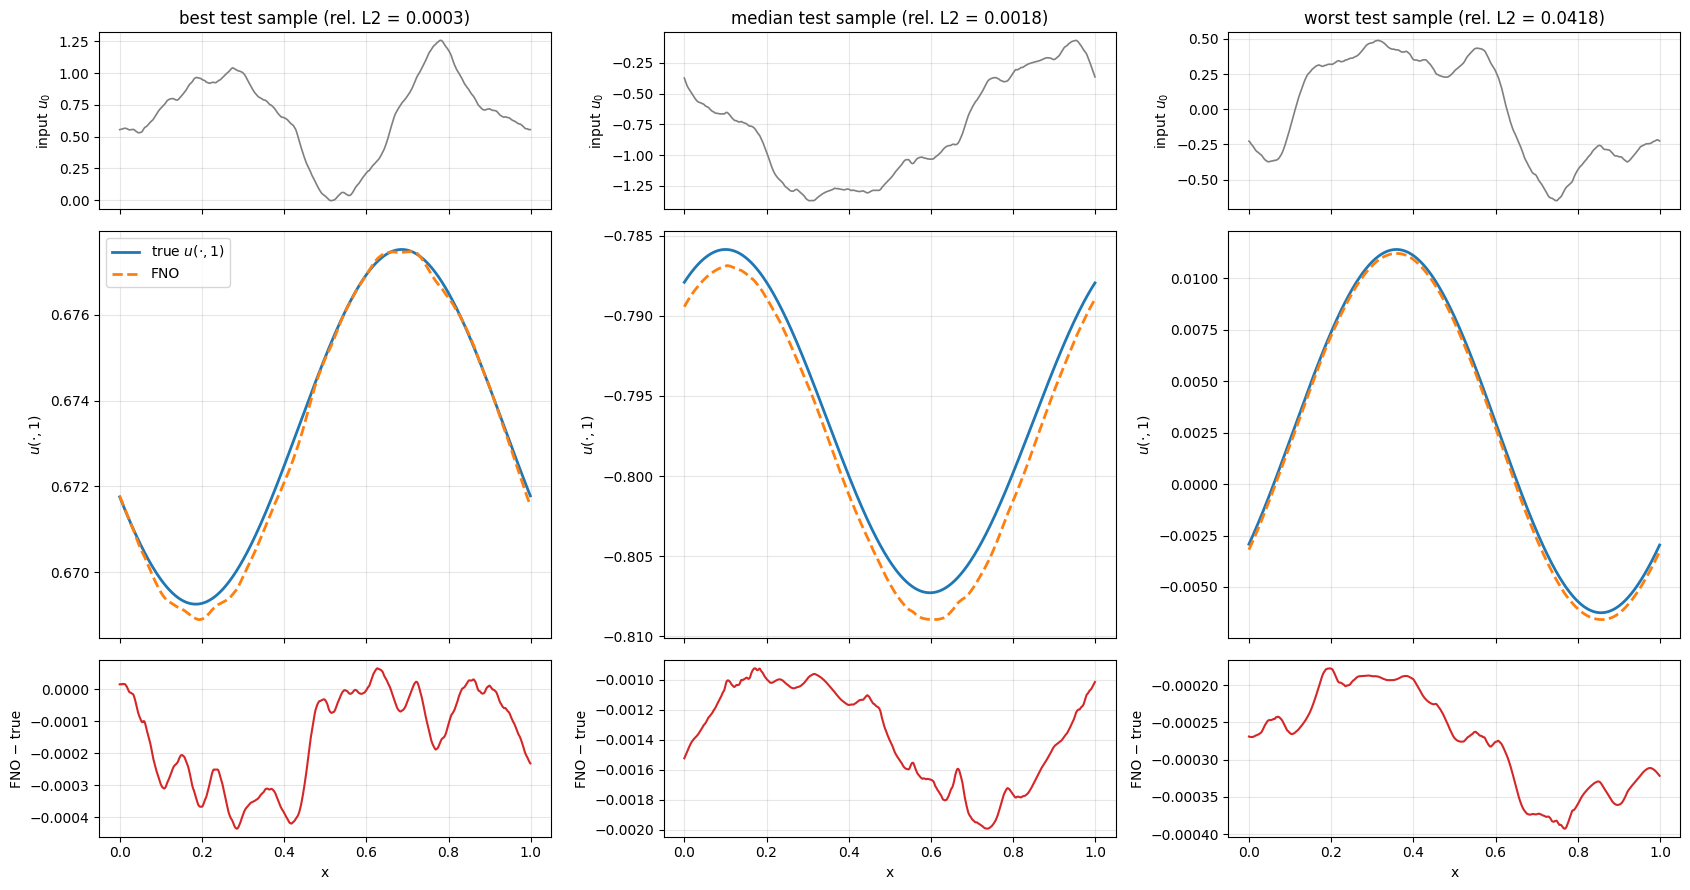

In [10]:
errs_test = evaluate(model, Xte, Yte)
order = torch.argsort(errs_test)
picks = [order[0].item(), order[len(order) // 2].item(), order[-1].item()]     # best, median, worst
labels = ["best", "median", "worst"]
xs = torch.arange(S_TRAIN) / S_TRAIN
with torch.no_grad():
    model.eval(); pred = model(Xte[picks]).cpu()

fig, axs = plt.subplots(3, 3, figsize=(17, 9), sharex=True, gridspec_kw={"height_ratios": [1.3, 3, 1.3]})
for j, (i, lab) in enumerate(zip(picks, labels)):
    axs[0, j].plot(xs, Xte[i].cpu(), color="0.5", lw=1.2)
    axs[0, j].set_ylabel(r"input $u_0$"); axs[0, j].grid(alpha=.3)
    axs[0, j].set_title(f"{lab} test sample (rel. L2 = {errs_test[i]:.4f})")
    axs[1, j].plot(xs, Yte[i].cpu(), lw=2, label=r"true $u(\cdot,1)$")
    axs[1, j].plot(xs, pred[j], "--", lw=2, label="FNO")
    axs[1, j].set_ylabel(r"$u(\cdot,1)$"); axs[1, j].grid(alpha=.3)
    axs[2, j].plot(xs, pred[j] - Yte[i].cpu(), color="C3"); axs[2, j].set_xlabel("x")
    axs[2, j].set_ylabel("FNO − true"); axs[2, j].grid(alpha=.3)
axs[1, 0].legend(); plt.tight_layout(); plt.show()
# Note: the relative error divides by ||u(.,1)||, so samples whose output is close to zero
# (mean of u0 near 0) have large relative errors even when the absolute error is tiny.

### 6c. Error distribution over the test set

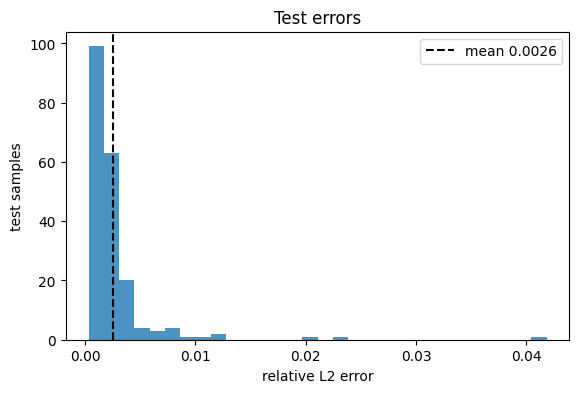

In [11]:
plt.figure(figsize=(6.5, 4))
plt.hist(errs_test.numpy(), bins=30, color="C0", alpha=.8)
plt.axvline(errs_test.mean(), color="k", ls="--", label=f"mean {errs_test.mean():.4f}")
plt.xlabel("relative L2 error"); plt.ylabel("test samples"); plt.legend(); plt.title("Test errors")
plt.show()

### 6d. Fourier spectra: does the FNO produce modes above $k_{\max}$?
The spectral weights act only on $|k| \le$ `MODES`. Higher modes in the output can only come from the
pointwise parts ($W$, the activation, $Q$). Compare the average spectrum of the truth and the prediction.

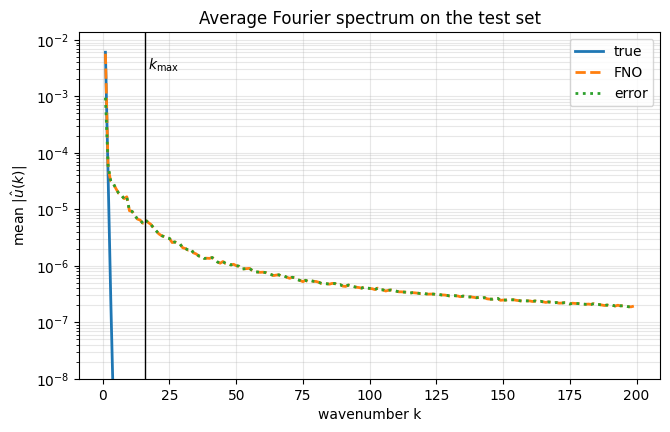

In [12]:
with torch.no_grad():
    P_all = torch.cat([model(Xte[i:i + 50]) for i in range(0, len(Xte), 50)]).cpu()
spec_true = torch.fft.rfft(Yte.cpu(), norm="forward").abs().mean(0)
spec_pred = torch.fft.rfft(P_all, norm="forward").abs().mean(0)
spec_err  = torch.fft.rfft(P_all - Yte.cpu(), norm="forward").abs().mean(0)
kgrid = torch.arange(spec_true.numel())
kmax_plot = min(200, spec_true.numel() - 1)
plt.figure(figsize=(7.5, 4.5))
plt.semilogy(kgrid[1:kmax_plot], spec_true[1:kmax_plot], lw=2, label="true")
plt.semilogy(kgrid[1:kmax_plot], spec_pred[1:kmax_plot], "--", lw=2, label="FNO")
plt.semilogy(kgrid[1:kmax_plot], spec_err[1:kmax_plot], ":", lw=2, label="error")
plt.axvline(MODES, color="k", lw=1); plt.text(MODES + 1, spec_true[1] * 0.5, r"$k_{\max}$")
plt.ylim(max(1e-8, spec_true[1:kmax_plot].min().item() * 0.5), None)   # below ~1e-8 is float32 round-off
plt.xlabel("wavenumber k"); plt.ylabel(r"mean $|\hat u(k)|$"); plt.grid(alpha=.3, which="both")
plt.title("Average Fourier spectrum on the test set"); plt.legend(); plt.show()

### 6e. Zero-shot evaluation at other resolutions
The **same** trained model is evaluated on the test set subsampled at resolutions it never saw.
(The paper's Table 3 instead trains a separate model per resolution; see 6f.)

s =   128: mean relative L2 = 0.0035
s =   256: mean relative L2 = 0.0030
s =   512: mean relative L2 = 0.0027
s =  1024: mean relative L2 = 0.0026   <- training resolution
s =  2048: mean relative L2 = 0.0025
s =  4096: mean relative L2 = 0.0025
s =  8192: mean relative L2 = 0.0025


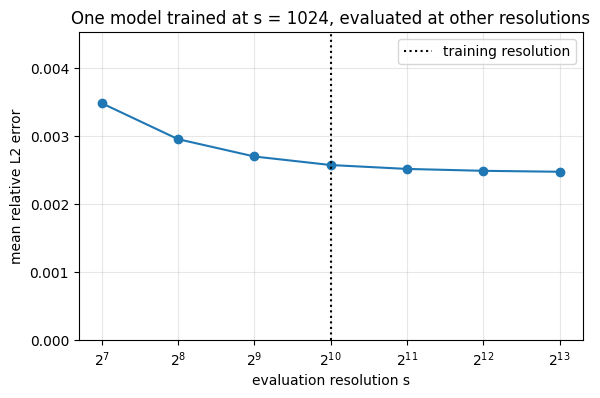

In [13]:
res_list = [s for s in [128, 256, 512, 1024, 2048, 4096, 8192] if N_SOLVE % s == 0 and s >= 2 * MODES]
zs = []
for s in res_list:
    st = N_SOLVE // s
    e = evaluate(model, u0_test[:, ::st].to(device), uT_test[:, ::st].to(device)).mean().item()
    zs.append(e); print(f"s = {s:5d}: mean relative L2 = {e:.4f}" + ("   <- training resolution" if s == S_TRAIN else ""))
plt.figure(figsize=(6.5, 4))
plt.semilogx(res_list, zs, "o-", base=2)
plt.axvline(S_TRAIN, color="k", ls=":", label="training resolution")
plt.xlabel("evaluation resolution s"); plt.ylabel("mean relative L2 error"); plt.ylim(0, max(zs) * 1.3)
plt.title(f"One model trained at s = {S_TRAIN}, evaluated at other resolutions"); plt.grid(alpha=.3); plt.legend()
plt.show()

### 6f. (Optional, slow) Table 3 protocol: train a separate model at each resolution
Set `RUN_SWEEP = True`. Each model takes roughly as long as the training above (longer at large s).

In [3]:
RUN_SWEEP = False
SWEEP_RES = [256, 512, 1024, 2048, 4096, 8192]

# Fallback values in case previous cells were not run
_epochs = globals().get('EPOCHS', 500)
_n_solve = globals().get('N_SOLVE', 8192)
_lr = globals().get('LR', 1e-3)
_weight_dec = globals().get('WEIGHT_DEC', 1e-4)
_step = globals().get('STEP', 100)
_gamma = globals().get('GAMMA', 0.5)
_batch = globals().get('BATCH', 20)
_n_train = globals().get('N_TRAIN', 1000)

SWEEP_EPOCHS = _epochs

if RUN_SWEEP:
    table = {}
    for s in [r for r in SWEEP_RES if _n_solve % r == 0]:
        st = _n_solve // s
        Xs, Ys = u0_train[:, ::st].to(device), uT_train[:, ::st].to(device)
        Xt, Yt = u0_test[:, ::st].to(device),  uT_test[:, ::st].to(device)
        m = FNO1d().to(device)
        o = torch.optim.Adam(m.parameters(), lr=_lr, weight_decay=_weight_dec)
        sc = torch.optim.lr_scheduler.StepLR(o, step_size=_step, gamma=_gamma)
        t0 = time.time()
        for ep in range(SWEEP_EPOCHS):
            m.train(); perm = torch.randperm(_n_train, device=device)
            for i in range(0, _n_train, _batch):
                idx = perm[i:i + _batch]
                l = rel_l2(m(Xs[idx]), Ys[idx]).mean()
                o.zero_grad(); l.backward(); o.step()
            sc.step()
        table[s] = evaluate(m, Xt, Yt).mean().item()
        print(f"s = {s:5d}: test error {table[s]:.4f}  ({time.time() - t0:.0f} s)")
    paper = {256: 0.0149, 512: 0.0158, 1024: 0.0160, 2048: 0.0146, 4096: 0.0142, 8192: 0.0139}
    plt.figure(figsize=(6.5, 4))
    plt.semilogx(list(table), list(table.values()), "o-", base=2, label="this run")
    plt.semilogx(list(paper), list(paper.values()), "s--", base=2, label="paper, Table 3")
    plt.xlabel("resolution s (train = test)"); plt.ylabel("relative L2 error"); plt.ylim(0, None)
    plt.grid(alpha=.3); plt.legend(); plt.title("Separate model per resolution"); plt.show()